<a href="https://colab.research.google.com/github/melaniela02/DSC_110/blob/main/Data_Summarization_and_Visualization_10_13_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt


In [5]:
df = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/nhanes_final.csv") #dataframe from pandas

In [6]:
df.head() #quick check

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN


Transforming variables

In [7]:
df['education'].unique() #unique values in education

array([ 5.,  3., nan,  2.,  4.,  1.,  9.])

In [9]:
education_map = { #creating dictionary
    1: 'Less than 9th grade',
    2: '9-11th grade',
    3: 'Highschool Grad',
    4: 'Some college or AA degree',
    5: 'College grad', #no six, seven, eight from above
    9: 'Do not know'
}

In [11]:
df['education_label'] = df['education'].map(education_map) #creating new field in dataframe

In [13]:
df.head() #check to see new field

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,College grad
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,College grad
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,Highschool Grad
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN


In [15]:
df['education_label'].value_counts()

,count
education_label,
College grad,2625
Some college or AA degree,2370
Highschool Grad,1749
9-11th grade,666
Less than 9th grade,373
Do not know,11


In [24]:
#Do the same for the diabetes field
#1 = has diabetes, 2= no diabtes, 3= borderline, 9=do not know
#name the new field diabetes_label
diabetes_map = { #creating dicitonary for diabetes map
    1: 'has diabetes',
    2: 'no diabetes',
    3: 'borderline',
    9: 'do not know'
}

In [25]:
df['diabetes_label'] = df['has_diabetes'].map(diabetes_map)

In [26]:
df.head() #checking diabetes label field

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label,diabetes_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,NaN,no diabetes
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,NaN,no diabetes
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,borderline,has diabetes
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN,no diabetes
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,no diabetes


In [28]:
df['diabetes_label'].value_counts() #seeing the diabetes value counts

,count
diabetes_label,
no diabetes,10371
has diabetes,1081
borderline,284
do not know,4


Data Summarization:
One numerical value

In [32]:
#Numerical variables in our data
avg_age = round(df['age'].mean(),2) #rounded to two decimals
print(f"the average age of NHANES respondents is {avg_age}") #prints with text

the average age of NHANES respondents is 38.32


In [38]:
df['age'].std() #standard deviation of age

25.60199011389104

In [37]:
df['age'].median() #median of age

37.0

In [36]:
df['age'].quantile([0.25]) #first quartile

,age
0.25,13.0


In [39]:
df['age'].quantile([0.75]) #third quartile

,age
0.75,62.0


In [40]:
df['age'].describe() #gives full summary of count, mean, std, min, 25-50-75% and max

,age
count,1.193300e+04
mean,3.831786e+01
std,2.560199e+01
min,5.397605e-79
25%,1.300000e+01
50%,3.700000e+01
75%,6.200000e+01
max,8.000000e+01


In [41]:
df['age'].mode()

,age
0,80.0


Data Visualization for One Numeric Variable

<Axes: >

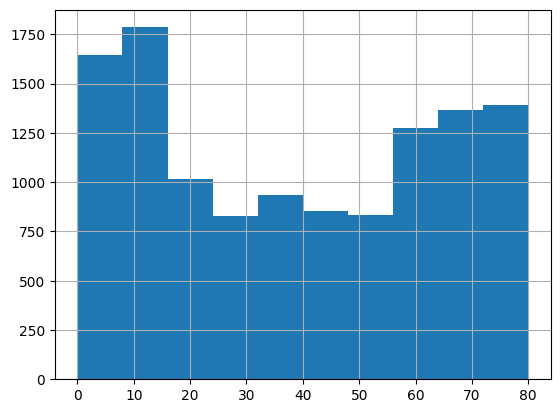

In [42]:
df['age'].hist() #creates histogram

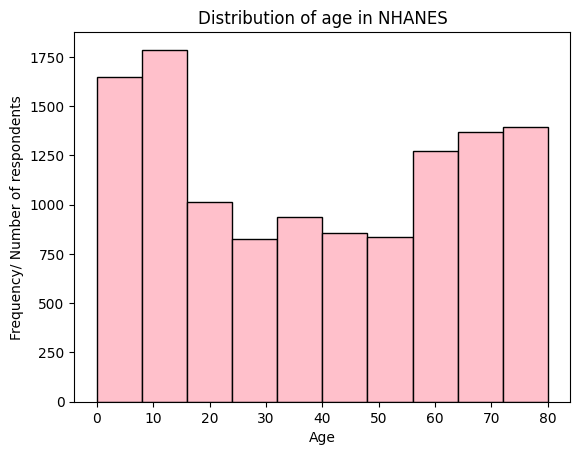

In [47]:
df['age'].hist(edgecolor = 'black', color = "pink") #changing color and edgecolors
#axis titles
plt.title("Distribution of age in NHANES")
plt.ylabel("Frequency/ Number of respondents")
plt.xlabel("Age")
plt.grid(False) #removes grid


Summarization and Visualization of one categorical/qualitative variable

In [49]:
df['education_label'].value_counts()

,count
education_label,
borderline,1749
no diabetes,666
has diabetes,373
do not know,11


In [50]:
df['education_label'].value_counts(normalize=True) * 100 #helping to get percentages

,proportion
education_label,
borderline,62.486602
no diabetes,23.794212
has diabetes,13.326188
do not know,0.392997


Text(0, 0.5, 'Number of respondents/Frequency')

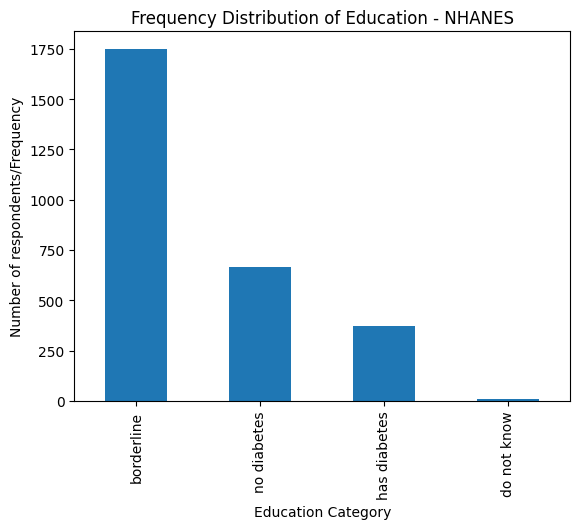

In [53]:
df['education_label'].value_counts().plot(kind='bar') #bar chart for education labels
#axis labels
plt.title('Frequency Distribution of Education - NHANES')
plt.xlabel('Education Category')
plt.ylabel('Number of respondents/Frequency')

Two numerical variables

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

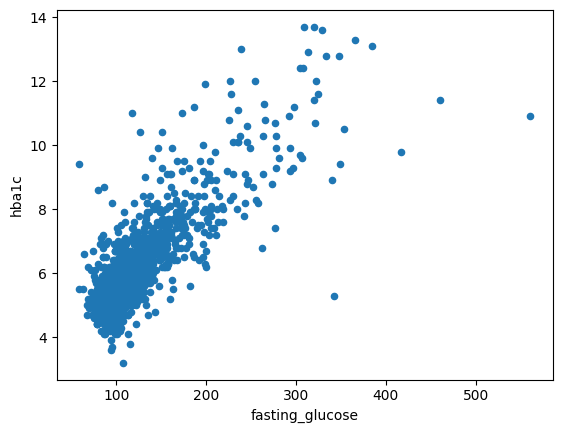

In [54]:
df.plot(x='fasting_glucose', y='hba1c', kind= 'scatter')


<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

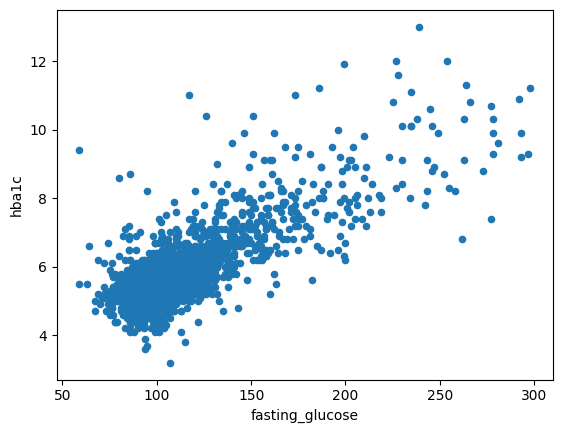

In [58]:
df_no_outliers = df[df['fasting_glucose'] < 300]
df_no_outliers.plot(x='fasting_glucose', y='hba1c', kind='scatter')

Two categorical values

In [61]:
df['bmi_category'] = pd.cut( #cutting into bins
    df['bmi'],
    bins=[0, 18.5, 25, 30, 100],
    labels=['underweight', 'normal', 'overweight', 'obese']
)

In [64]:
pd.crosstab(df['bmi_category'],df['diabetes_label'], normalize='index') * 100 #added percentages

diabetes_label,borderline,do not know,has diabetes,no diabetes
bmi_category,,,,
underweight,0.000000,0.082237,0.328947,99.588816
normal,1.625000,0.041667,4.541667,93.791667
overweight,3.197807,0.000000,10.644130,86.158063
obese,4.501125,0.000000,18.904726,76.594149


<Axes: xlabel='bmi_category'>

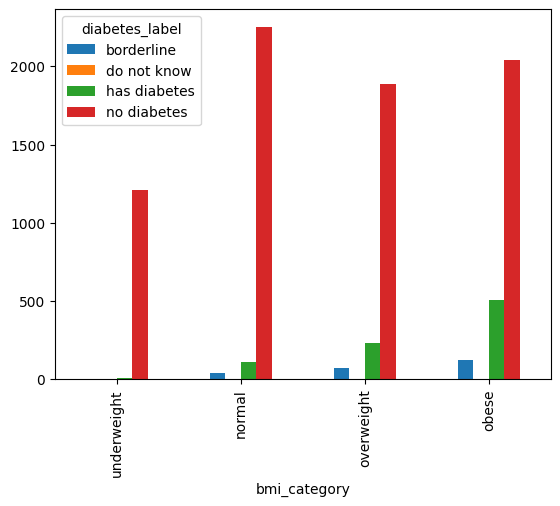

In [65]:
pd.crosstab(df['bmi_category'], df['diabetes_label'] ).plot(kind = 'bar') #making into bar chart

One numerical and one categorical

In [66]:
df.groupby('diabetes_label')['bmi'].mean()

,bmi
diabetes_label,
borderline,32.068559
do not know,19.250000
has diabetes,32.981412
no diabetes,26.439797


Text(0, 0.5, 'BMI')

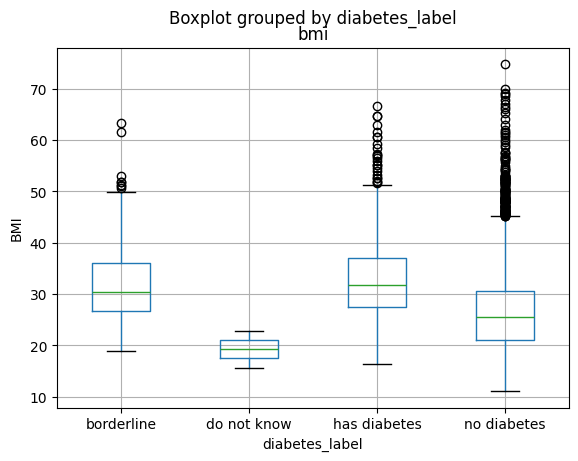

In [68]:
#boxplot
df.boxplot(column='bmi', by='diabetes_label')
plt.ylabel('BMI')